In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from neural_network import SelfOrganizingMaps

In [2]:
X = load_wine(as_frame=True).data

In [3]:
som = SelfOrganizingMaps(data=X, x_neuron=8, y_neuron=8, n_iter=8000, random_state=42)
som.fit_train(steps=100)                               # record QE/TE every 100 iterations

In [4]:
bmu, index_bmu, distance = som.predict()               # training data
bmu_new, idx_new, d_new = som.predict(X.iloc[:5])      # new data, original units

In [5]:
hit_map  = som.heat_maps()                             # tensor (8, 8)
u_matrix = som.u_matrix()                              # tensor (8, 8)

In [6]:
w_original = som.scaler.inverse_transform(som.final_weight.numpy())
profile = pd.DataFrame(w_original, columns=X.columns)

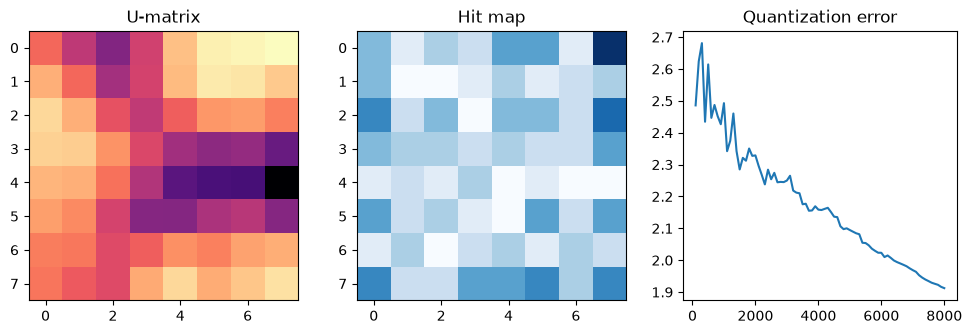

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
ax[0].imshow(u_matrix.numpy(), cmap="magma_r"); ax[0].set_title("U-matrix")
ax[1].imshow(hit_map.numpy(),  cmap="Blues");   ax[1].set_title("Hit map")
ax[2].plot(som.iter_steps, [float(q) for q in som.quantization_err])
ax[2].set_title("Quantization error")
plt.show()